In [113]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

benzo=0
n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3


# Benzodiazepines/GABA agonist effect strengths (fractions)
Ben_GABA_E = 5.0   # X% increase of inhibitory drive onto E

kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(42,47),range(32,37)]).flatten()]=0



def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(training):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E    * k_GABA_E_hsp * (1 + Ben_GABA_E * benzo) * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    benzo = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * g_AMPA_I_hsp * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * g_GABA_I_hsp * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    dg_AMPA_I_hsp/dt = ((1 - g_AMPA_I_hsp) * clip((-r_est +target_rate)/target_rate, 0, 1) / tau_ins_AMPA_I
                - (g_AMPA_I_hsp - 0.1) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_int_AMPA_I) : 1

    dg_GABA_I_hsp/dt = (-(g_GABA_I_hsp - 0.1) * clip((-r_est + target_rate)/target_rate, 0, 1) / tau_int_GABA_I
                + (1 - g_GABA_I_hsp) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_ins_GABA_I) : 1


    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_I : second (shared)
    tau_int_AMPA_I : second (shared)
    tau_int_GABA_I : second (shared)
    tau_ins_GABA_I : second (shared)
    '''

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.3  
    P_E.k_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = 500*second   #50'000
    P_E.tau_int_AMPA_E = 50*second    #5'000
    P_E.tau_ins_GABA_E = 100*second   
    P_E.tau_int_GABA_E = 50*second   

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_I.g_AMPA_I_hsp = 0.3  
    P_I.g_GABA_I_hsp = 0.3  
    P_I.tau_ins_AMPA_I = 500000000*second   
    P_I.tau_int_AMPA_I = 50000000*second    
    P_I.tau_ins_GABA_I = 500000000*second   
    P_I.tau_int_GABA_I = 50000000*second



    P_E.t_on  = 100000*second
    P_E.t_off = 10000*second#700*second#1000*second


    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    if training :
        #STDP
        stdp_eqs = '''
        w : 1
        dpre/dt = -pre/ taupre : 1 (event-driven)
        dpost/dt = -post/ taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_stdp = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        '''
        on_pre_stdp_EI = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        x_postE_post += 1.0 / N_incoming_post
        '''
        on_post_stdp = '''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
        '''
        #iSTDP
        iSTDP_eqs = '''
        w : 1
        dpre/dt = -pre / taupre : 1 (event-driven)
        dpost/dt = -post / taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_iSTDP = '''
        s_GABA += w
        pre += 1.
        w = clip(w + Apost_i * post, 0, w_max_i)
        '''
        on_post_iSTDP = '''
        post += 1.
        w = clip(w + Apre_i * pre, 0, w_max_i)
        '''
        # E to E
        C_E_E = Synapses(P_E, P_E,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_E')
        #C_E_E.connect('i != j')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)

        C_E_E.taupre = 20*ms
        C_E_E.taupost = 20*ms

        # E to I to E
        C_E_I = Synapses(P_E, P_I,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp_EI,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_I')

        C_I_E = Synapses(P_I, P_E,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_E')
        
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        
        C_E_I.taupre = 20*ms
        C_E_I.taupost = 20*ms
        C_I_E.taupre = 20*ms
        C_I_E.taupost = 20*ms

        # I to I
        C_I_I = Synapses(P_I, P_I,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)

        C_I_I.taupre = 20*ms
        C_I_I.taupost = 20*ms
        
        C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
                s_AMPA_ext += w
                pre += 1.
                w = clip(w + Apost * post, 0, w_max)
            ''',
            on_post='''
                post += 1.
                w = clip(w + Apre * pre, 0, w_max)
            ''',
            method='euler', name='PG_E')
        C_PG_E.connect(j='i')                 

        C_PG_E.taupre = 20*ms
        C_PG_E.taupost = 20*ms

    else:
        C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
            s_AMPA_ext += w  
            ''', method='euler', name='PG_E')
        C_PG_E.connect(j='i')  

        
        C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
            s_AMPA += w  
            ''', method='euler', name='E_E')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)
        C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
        s_AMPA += w
        ''', method='euler', name='E_I') #        x_postE_post += 1.0 
        C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)
    
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)
        C_I_E.w[:] = 0.2
        C_I_I.w[:] = 0.2
        C_E_I.w[:] = 0.6
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.08, size=len(C_E_E.w)), 0.0, 1.0) 
    else:
        # w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        # w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        # w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        # w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        # w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
        C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
        C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
        C_E_I.w[:] = 0.6 #np.clip(np.random.normal(loc=0.50, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')
    # gAMPA_mon_I = StateMonitor(P_I, 'g_AMPA_I_hsp', record=True, dt=record_dt, name='g_AMPA_I_hsp')
    # gGABA_mon_I = StateMonitor(P_I, 'g_GABA_I_hsp', record=True, dt=record_dt, name='g_GABA_I_hsp')

    # sp_PG = SpikeMonitor(pg_inp, name = 'sp_inp')
    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')

# def train(N_train,alcohol,target_rate = 10*Hz):
#     net = build_network(True,alcohol=alcohol,target_rate=target_rate)
#     for i in range(N_train): 
#         show_img(net, index = i)
#         print(i)

#     save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
#     save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
#     save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
#     save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
#     save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
#     return net


def test(N_test,show_time = 1000*ms):
    net = build_network(False)
    for i in range(N_test):
        show_rand_rate(net,show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net

def kuramoto_r_from_spikes(spike_monitor, N, t_grid_s):
    spk_by_neuron = [np.asarray(spike_monitor.t[spike_monitor.i==j]/second, dtype=float)
                     for j in range(N)]
    for j in range(N):
        s = spk_by_neuron[j]
        if s.size == 0:
            spk_by_neuron[j] = np.array([-1e9, 1e9], dtype=float)
        else:
            spk_by_neuron[j] = np.concatenate(([-1e9], s, [1e9]))

    phases = np.empty((N, t_grid_s.size), dtype=float)
    for j in range(N):
        s = spk_by_neuron[j]
        idx = np.searchsorted(s, t_grid_s, side='right')  
        t_prev = s[idx-1]
        t_next = s[idx]
        denom = np.maximum(t_next - t_prev, 1e-12)
        frac = np.clip((t_grid_s - t_prev)/denom, 0.0, 1.0)
        phases[j, :] = 2*np.pi*frac

    z = np.exp(1j*phases).mean(axis=0)
    r = np.abs(z)
    return r


INFO:root:building '_cython_magic_7124b0be16cbee2f581e658baa31e06f' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_7124b0be16cbee2f581e658baa31e06f.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_7124b0be16cbee2f581e658baa31e06f.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_7124b0be16cbee2f581e658baa31e06f.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([38.4564993 , 41.93693609, 38.77173335, ..., 44.76540315,
       40.94451234, 39.61414877]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 20. ks
154.227 s (0%) simulated in 10s, estimated 21m 27s remaining.
304.278 s (1%) simulated in 20s, estimated 21m 35s remaining.
0.455323 ks (2%) simulated in 30s, estimated 21m 28s remaining.
0.591521 ks (2%) simulated in 40s, estimated 21m 52s remaining.
0.744458 ks (3%) simulated in 50s, estimated 21m 33s remaining.
0.898299 ks (4%) simulated in 1m 0s, estimated 21m 16s remaining.
1.030791 ks (5%) simulated in 1m 10s, estimated 21m 28s remaining.
1.184693 ks (5%) simulated in 1m 20s, estimated 21m 11s remaining.
1.333594 ks (6%) simulated in 1m 30s, estimated 21m 0s remaining.
1.464055 ks (7%) simulated in 1m 40s, estimated 21m 6s remaining.
1.616352 ks (8%) simulated in 1m 50s, estimated 20m 51s remaining.
1.766565 ks (8%) simulated in 2m 0s, estimated 20m 39s remaining.
1.90711 ks (9%) simulated in 2m 10s, estimated 20m 33s remaining.
2.031609 ks (10%) simulated in 2m 20s, estimated 20m 38s remaining.
2.167069 ks (10%) simulated in

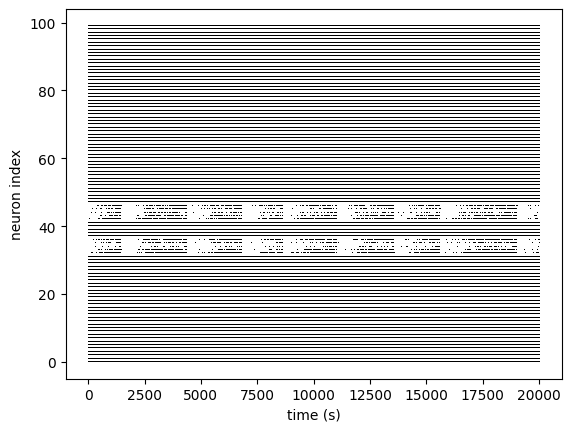

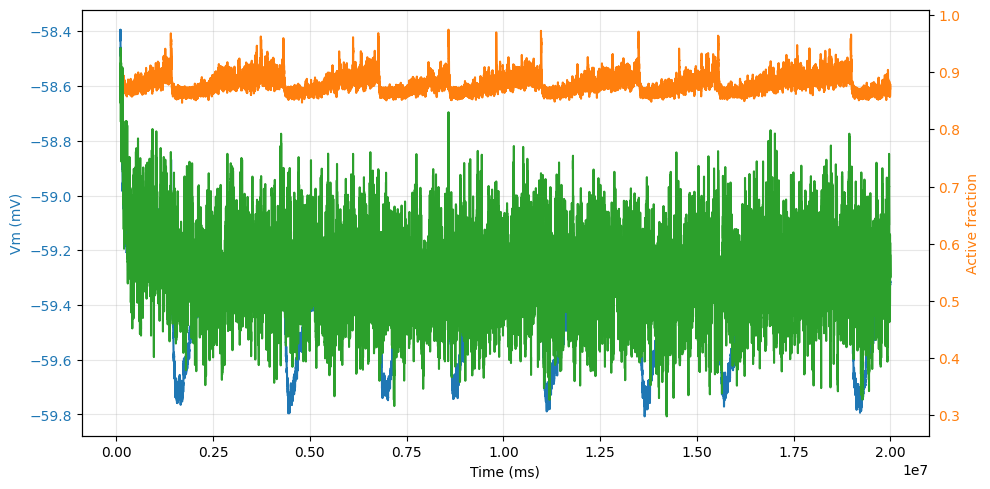

In [114]:
start_scope()
defaultclock.dt = 1000 * us
net = test(1,show_time=20000*second)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.1 
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

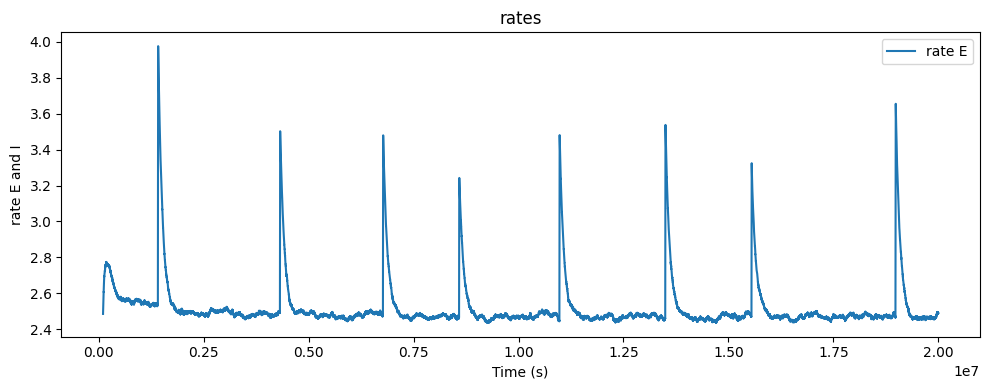

In [115]:
r_est_E = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E and I')
plt.title('rates')
plt.legend()
plt.tight_layout()

Benzo, increase k_GABA_E by (1+g_benzo) and w_I_E to 1

In [ ]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3


# Benzodiazepines/GABA agonist effect strengths (fractions)
#Ben_GABA_E = 5.0   # X% increase of inhibitory drive onto E

kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(42,47),range(32,37)]).flatten()]=0



def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(training):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E  * (k_GABA_E_hsp *(1-benzo)+ (1 * benzo)) * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    benzo = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * g_AMPA_I_hsp * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * g_GABA_I_hsp * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    dg_AMPA_I_hsp/dt = ((1 - g_AMPA_I_hsp) * clip((-r_est +target_rate)/target_rate, 0, 1) / tau_ins_AMPA_I
                - (g_AMPA_I_hsp - 0.1) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_int_AMPA_I) : 1

    dg_GABA_I_hsp/dt = (-(g_GABA_I_hsp - 0.1) * clip((-r_est + target_rate)/target_rate, 0, 1) / tau_int_GABA_I
                + (1 - g_GABA_I_hsp) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_ins_GABA_I) : 1


    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_I : second (shared)
    tau_int_AMPA_I : second (shared)
    tau_int_GABA_I : second (shared)
    tau_ins_GABA_I : second (shared)
    '''

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.3  
    P_E.k_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = 500*second   #50'000
    P_E.tau_int_AMPA_E = 50*second    #5'000
    P_E.tau_ins_GABA_E = 100*second   
    P_E.tau_int_GABA_E = 50*second   

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_I.g_AMPA_I_hsp = 0.3  
    P_I.g_GABA_I_hsp = 0.3  
    P_I.tau_ins_AMPA_I = 500000000*second   
    P_I.tau_int_AMPA_I = 50000000*second    
    P_I.tau_ins_GABA_I = 500000000*second   
    P_I.tau_int_GABA_I = 50000000*second



    P_E.t_on  = 20000*second
    P_E.t_off = 40000*second#700*second#1000*second


    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    if training :
        #STDP
        stdp_eqs = '''
        w : 1
        dpre/dt = -pre/ taupre : 1 (event-driven)
        dpost/dt = -post/ taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_stdp = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        '''
        on_pre_stdp_EI = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        x_postE_post += 1.0 / N_incoming_post
        '''
        on_post_stdp = '''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
        '''
        #iSTDP
        iSTDP_eqs = '''
        w : 1
        dpre/dt = -pre / taupre : 1 (event-driven)
        dpost/dt = -post / taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_iSTDP = '''
        s_GABA += w
        pre += 1.
        w = clip(w + Apost_i * post, 0, w_max_i)
        '''
        on_post_iSTDP = '''
        post += 1.
        w = clip(w + Apre_i * pre, 0, w_max_i)
        '''
        # E to E
        C_E_E = Synapses(P_E, P_E,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_E')
        #C_E_E.connect('i != j')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)

        C_E_E.taupre = 20*ms
        C_E_E.taupost = 20*ms

        # E to I to E
        C_E_I = Synapses(P_E, P_I,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp_EI,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_I')

        C_I_E = Synapses(P_I, P_E,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_E')
        
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        
        C_E_I.taupre = 20*ms
        C_E_I.taupost = 20*ms
        C_I_E.taupre = 20*ms
        C_I_E.taupost = 20*ms

        # I to I
        C_I_I = Synapses(P_I, P_I,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)

        C_I_I.taupre = 20*ms
        C_I_I.taupost = 20*ms
        
        C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
                s_AMPA_ext += w
                pre += 1.
                w = clip(w + Apost * post, 0, w_max)
            ''',
            on_post='''
                post += 1.
                w = clip(w + Apre * pre, 0, w_max)
            ''',
            method='euler', name='PG_E')
        C_PG_E.connect(j='i')                 

        C_PG_E.taupre = 20*ms
        C_PG_E.taupost = 20*ms

    else:
        C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
            s_AMPA_ext += w  
            ''', method='euler', name='PG_E')
        C_PG_E.connect(j='i')  

        
        C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
            s_AMPA += w  
            ''', method='euler', name='E_E')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)
        C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
        s_AMPA += w
        ''', method='euler', name='E_I') #        x_postE_post += 1.0 
        C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)
    
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)
        C_I_E.w[:] = 0.2
        C_I_I.w[:] = 0.2
        C_E_I.w[:] = 0.6
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.08, size=len(C_E_E.w)), 0.0, 1.0) 
    else:
        # w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        # w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        # w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        # w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        # w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
        C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
        C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
        C_E_I.w[:] = 0.6 #np.clip(np.random.normal(loc=0.50, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')
    # gAMPA_mon_I = StateMonitor(P_I, 'g_AMPA_I_hsp', record=True, dt=record_dt, name='g_AMPA_I_hsp')
    # gGABA_mon_I = StateMonitor(P_I, 'g_GABA_I_hsp', record=True, dt=record_dt, name='g_GABA_I_hsp')

    # sp_PG = SpikeMonitor(pg_inp, name = 'sp_inp')
    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')

# def train(N_train,alcohol,target_rate = 10*Hz):
#     net = build_network(True,alcohol=alcohol,target_rate=target_rate)
#     for i in range(N_train): 
#         show_img(net, index = i)
#         print(i)

#     save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
#     save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
#     save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
#     save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
#     save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
#     return net


def test(N_test,show_time = 1000*ms):
    net = build_network(False)
    for i in range(N_test):
        show_rand_rate(net,show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net

def kuramoto_r_from_spikes(spike_monitor, N, t_grid_s):
    spk_by_neuron = [np.asarray(spike_monitor.t[spike_monitor.i==j]/second, dtype=float)
                     for j in range(N)]
    for j in range(N):
        s = spk_by_neuron[j]
        if s.size == 0:
            spk_by_neuron[j] = np.array([-1e9, 1e9], dtype=float)
        else:
            spk_by_neuron[j] = np.concatenate(([-1e9], s, [1e9]))

    phases = np.empty((N, t_grid_s.size), dtype=float)
    for j in range(N):
        s = spk_by_neuron[j]
        idx = np.searchsorted(s, t_grid_s, side='right')  
        t_prev = s[idx-1]
        t_next = s[idx]
        denom = np.maximum(t_next - t_prev, 1e-12)
        frac = np.clip((t_grid_s - t_prev)/denom, 0.0, 1.0)
        phases[j, :] = 2*np.pi*frac

    z = np.exp(1j*phases).mean(axis=0)
    r = np.abs(z)
    return r


INFO:root:building '_cython_magic_98d081464ae0aada9a8eb4edd4de0558' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_98d081464ae0aada9a8eb4edd4de0558.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_98d081464ae0aada9a8eb4edd4de0558.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_98d081464ae0aada9a8eb4edd4de0558.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([40.21030558, 39.9499826 , 38.82950811, ..., 40.90649122,
       35.46917105, 46.27489   ]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 40. ks
163.952 s (0%) simulated in 10s, estimated 40m 30s remaining.
293.596 s (0%) simulated in 20s, estimated 45m 5s remaining.
0.456536 ks (1%) simulated in 30s, estimated 43m 18s remaining.
0.616324 ks (1%) simulated in 40s, estimated 42m 36s remaining.
0.72844 ks (1%) simulated in 50s, estimated 44m 56s remaining.
0.887243 ks (2%) simulated in 1m 0s, estimated 44m 5s remaining.
1.055514 ks (2%) simulated in 1m 10s, estimated 43m 3s remaining.
1.22124 ks (3%) simulated in 1m 20s, estimated 42m 20s remaining.
1.353721 ks (3%) simulated in 1m 30s, estimated 42m 49s remaining.
1.519845 ks (3%) simulated in 1m 40s, estimated 42m 12s remaining.
1.690552 ks (4%) simulated in 1m 50s, estimated 41m 33s remaining.
1.822275 ks (4%) simulated in 2m 0s, estimated 41m 54s remaining.
1.986526 ks (4%) simulated in 2m 10s, estimated 41m 28s remaining.
2.135735 ks (5%) simulated in 2m 20s, estimated 41m 22s remaining.
2.279569 ks (5%) simulated in 2m 

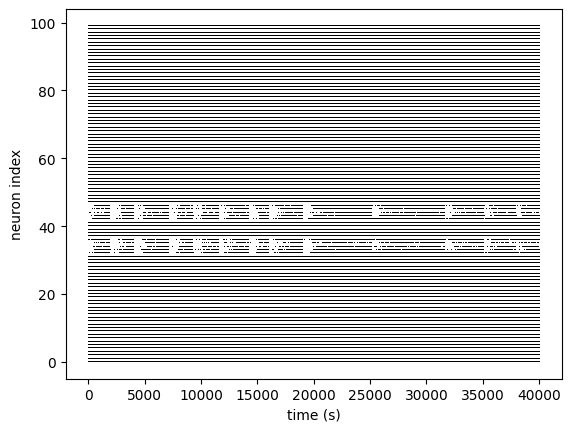

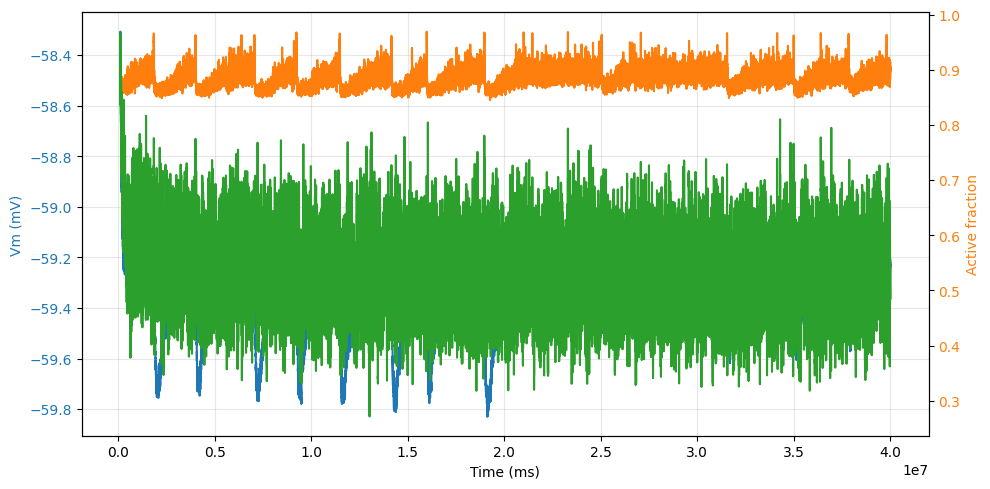

In [128]:
start_scope()
defaultclock.dt = 1000 * us
net = test(1,show_time=40000*second)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

# step=0.1 
# t_end=V_mon.t[-1]/second
# t_grid = np.arange(0.0, t_end + step, step)
# rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
# rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

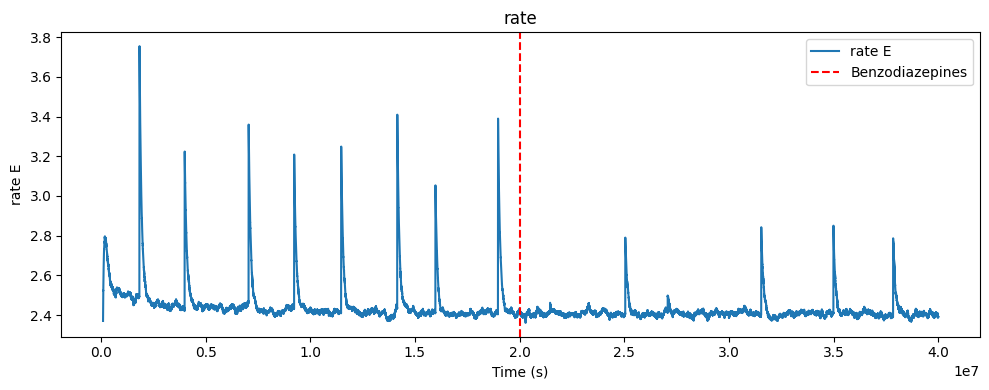

In [129]:
r_est_E = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.axvline(x=20000000, color='r', linestyle='--', label='Benzodiazepines')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()